<a href="https://colab.research.google.com/github/nurfahdilla293/praktikum_evaluasi_model.ipynb/blob/main/Praktikum_1_ML_Iris_KNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Machine Learning Bab 1: Alur Kerja ML End-to-End
**Studi kasus:** Klasifikasi bunga Iris dengan K-Nearest Neighbors (KNN)

Alur yang dikerjakan: persiapan library → import dataset → eksplorasi awal → training model → evaluasi → visualisasi → interpretasi.

## Praktikum 1.1 Persiapan Library

In [1]:
# Menjalankan di Google Colab / Jupyter Notebook
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

print("Library berhasil dimuat.")

Library berhasil dimuat.


## Praktikum 1.2 Import Dataset
Dataset Iris tersedia langsung di Scikit-learn (3 kelas spesies bunga iris).

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame
df['target_name'] = df['target'].map(dict(enumerate(iris.target_names)))

print("Ukuran dataset:", df.shape)
df.head()

Ukuran dataset: (150, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,target_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## Praktikum 1.3 Preprocessing (Eksplorasi Awal)

In [3]:
print(df.info())
print("\nJumlah data per kelas:")
print(df['target_name'].value_counts())

X = df[iris.feature_names]
y = df['target']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   target_name        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB
None

Jumlah data per kelas:
target_name
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## Praktikum 1.4 Training Model
Data dibagi menjadi data latih dan data uji (80:20, stratified), lalu model KNN dilatih sebagai model ML pertama.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

model = KNeighborsClassifier(n_neighbors=3)
model.fit(X_train, y_train)

print("Model berhasil dilatih pada", X_train.shape[0], "data latih.")

Model berhasil dilatih pada 120 data latih.


## Praktikum 1.5 Evaluasi

In [5]:
y_pred = model.predict(X_test)
akurasi = accuracy_score(y_test, y_pred)
print(f"Akurasi model pada data uji: {akurasi:.2%}")

Akurasi model pada data uji: 100.00%


## Praktikum 1.6 Visualisasi

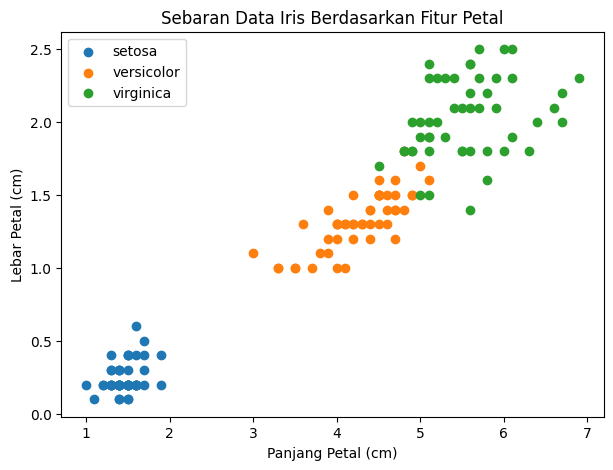

In [6]:
plt.figure(figsize=(7, 5))
for target_value, target_name in enumerate(iris.target_names):
    subset = df[df['target'] == target_value]
    plt.scatter(subset['petal length (cm)'],
                subset['petal width (cm)'], label=target_name)

plt.xlabel('Panjang Petal (cm)')
plt.ylabel('Lebar Petal (cm)')
plt.title('Sebaran Data Iris Berdasarkan Fitur Petal')
plt.legend()
plt.show()

## Interpretasi
Dari visualisasi sebaran data, ketiga kelas bunga iris (setosa, versicolor, virginica) membentuk kelompok yang cukup terpisah berdasarkan fitur panjang dan lebar petal. Kelas setosa terpisah sangat jelas, sedangkan versicolor dan virginica hanya sedikit beririsan di bagian perbatasan. Karena itu wajar apabila model KNN memperoleh akurasi yang tinggi (umumnya di atas 90%).

ini menunjukkan alur kerja ML end-to-end paling sederhana: **data dimuat → dibagi menjadi train/test → model dilatih → dievaluasi**. Pola alur inilah yang akan terus berulang, dengan tingkat kerumitan yang meningkat.